# 04 · Makine öğrenmesi ve arıza tahmini

**Denetimli öğrenme (Supervised Learning)** örneklerle birlikte verilen doğru sonuçlardan öğrenir. Burada ürün tipi ile beş sensör ölçümünü kullanarak arıza durumunu tahmin ediyoruz. Sonuç normal (0) veya arıza (1) olduğundan bu bir **ikili sınıflandırma (Binary Classification)** problemidir.

AI4I 2020 sentetik bir veri setidir. Sonuçlar gerçek fabrikalardaki performansı garanti etmez.

## 1. Ortak kodu yükleme

Notebook ve komut satırının aynı veri okuma, ön işleme ve değerlendirme adımlarını uygulaması için proje modüllerini içe aktarıyoruz. Notebook hem proje kökünden hem de notebooks klasöründen açılabilir.

In [1]:
from pathlib import Path
import sys
from IPython.display import Image, display
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from src.preprocessing import split_data
from src.train_models import load_training_data, build_models, compare_models, fit_model
from src.evaluate_models import RESULTS, evaluate, save_results

## 2. Eğitim görünümünü okuma ve veriyi ayırma

PostgreSQL’den yalnızca model girdilerini ve hedefi okuyoruz. Tekrarlanabilir sıralamadan sonra 10.000 kaydı doğruluyoruz. Arıza türü bayrakları ve kayıt kimlikleri görünümün dışındadır. Tahmin anında bilinmeyen arıza bayrakları kullanılsaydı **veri sızıntısı** oluşabilirdi.

Arıza seyrek olduğu için **sınıf dengesizliği (Class Imbalance)** vardır. Stratify, %80 eğitim ve %20 test ayrımında arıza oranını yaklaşık olarak korur. Sabit random_state aynı satırların tekrar seçilmesini sağlar.

In [2]:
X, y = load_training_data()
X_train, X_test, y_train, y_test = split_data(X, y)
display(pd.DataFrame({
    "Kayıt": [len(y), len(y_train), len(y_test)],
    "Arıza": [y.sum(), y_train.sum(), y_test.sum()],
    "Arıza oranı": [y.mean(), y_train.mean(), y_test.mean()],
}, index=["Toplam", "Eğitim", "Test"]))

,Kayıt,Arıza,Arıza oranı
Toplam,10000,339,0.033900
Eğitim,8000,271,0.033875
Test,2000,68,0.034000


## 3. Karşılaştırılacak modeller

**Baseline Model (referans model)**, öğrenen modellerin koşullara uyum sağlamadan elde edilebilecek sonuca göre ne kadar iyileştiğini gösterir.

| Model | Çalışma mantığı | Avantaj | Dezavantaj | Kullanım örneği |
| --- | --- | --- | --- | --- |
| Dummy Classifier | En sık görülen sınıfı seçer. | Basit bir referans verir. | Arızaları ayırt edemez. | Modelin öğrenme sağladığını kontrol etmek. |
| Logistic Regression | Ölçümlerin ağırlıklı toplamından arıza olasılığı hesaplar. | Hızlı ve açıklanabilir. | Karmaşık ilişkileri yakalamakta zorlanır. | İlk risk tahmini. |
| Decision Tree | Ölçümleri eşiklerle dallara ayırır. | Karar kuralları izlenebilir. | Derin ağaç örnekleri ezberleyebilir. | Arıza eşiklerini incelemek. |
| Random Forest | Farklı örneklerle eğitilen ağaçların kararlarını birleştirir. | Tek ağaca göre genellikle daha kararlıdır. | Daha çok hesaplama gerektirir. | Tablo biçimindeki sensör verisinde etkileşimleri öğrenmek. |
| SVM | Normal ve arızalı örnekler arasında geniş bir karar marjı arar. | RBF çekirdeği eğri sınırları yakalayabilir. | Ölçeklemeye duyarlıdır. | Karmaşık çalışma bölgelerini ayırmak. |
| XGBoost | Yeni ağaçları sırayla ekleyerek hataları azaltır. | Sensör etkileşimlerini yakalayabilir. | Ayarları ve kararları yorumlamak güçleşebilir. | Arıza riskine göre sıralama yapmak. |

**Hiperparametre**, eğitim öncesi seçilen bir ayardır. Ağaç sayısı veya öğrenme oranı buna örnektir. Burada sabit ayarlar kullanıyoruz. Dummy dışındaki modeller arızalı örneklere sınıf ağırlığı veya eğitim katına özel örnek ağırlığı verir. Her model, mevcut ölçekleyici ve kategorik kodlayıcıyla bir Pipeline oluşturur.

In [3]:
models = build_models()
list(models)

['Dummy Classifier',
 'Logistic Regression',
 'Decision Tree',
 'Random Forest',
 'SVM',
 'XGBoost']

## 4. Beş katlı çapraz doğrulama ve model seçimi

**Cross Validation (çapraz doğrulama)** 8.000 eğitim satırını beş tabakalı kata ayırır. Dört kat Pipeline’ı eğitir, biri doğrular. Her turda ölçekleme ve kodlama yalnızca dört eğitim katında öğrenilir. Bütün modeller aynı katlarda ölçülür.

**Overfitting (aşırı uyum)**, eğitim örneklerinin ayrıntılarını ezberleyip yeni örneklerde zayıf kalmaktır. **Underfitting (yetersiz uyum)**, hem eğitim hem doğrulamada örüntüyü öğrenememektir. Bu tablo doğrulama performansını gösterir. İkisini ayırt etmek için eğitim sonuçlarıyla birlikte incelemek gerekir.

Accuracy tüm doğru tahminlerin oranıdır. Balanced Accuracy, normal ve arızalı sınıfların ayrı ayrı yakalanma oranlarının ortalamasıdır. **Precision** arıza alarmı verilen örneklerin ne kadarının gerçekten arızalı olduğunu, **Recall** gerçek arızaların ne kadarının yakalandığını ölçer. **F1**, bu iki oranın harmonik ortalamasıdır.

**ROC-AUC** farklı eşiklerde arızaları normallerin önünde sıralama becerisini özetler. **Precision–Recall eğrisi** eşik değiştikçe alarm isabetinin ve yakalanan arıza oranının nasıl değiştiğini gösterir. **Average Precision (AP)** bu eğriyi özetler. Arızalar seyrek olduğu için seçimi ortalama AP ile yapıyoruz. Eşitlikte önce F1, ardından model adı kullanılır. Test kümesi bu adıma girmez.

**Confusion Matrix (hata matrisi)** doğru normal (TN), yanlış alarm (FP), kaçırılan arıza (FN) ve doğru arıza (TP) sayılarını gösterir. Tablodaki sayılar beş doğrulama katının toplamıdır. Eğitim süresi Pipeline’ın fit süresidir.

In [4]:
comparison = compare_models(models, X_train, y_train)
winner = comparison.iloc[0]["model"]
mean_columns = [column for column in comparison if column.endswith("_mean")]
display(comparison[["model", *mean_columns, "tn", "fp", "fn", "tp"]].round(4))
print(f"Seçilen model: {winner}")

,model,accuracy_mean,balanced_accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,average_precision_mean,fit_seconds_mean,tn,fp,fn,tp
0,XGBoost,0.9496,0.8973,0.3902,0.8412,0.5314,0.9740,0.7643,0.1608,7369,360,43,228
1,Random Forest,0.9776,0.6874,0.9158,0.3761,0.5309,0.9625,0.7515,0.7427,7719,10,169,102
2,SVM,0.9162,0.9032,0.2745,0.8892,0.4190,0.9624,0.6442,0.2518,7089,640,30,241
3,Logistic Regression,0.8262,0.8192,0.1412,0.8116,0.2405,0.9030,0.4341,0.0182,6390,1339,51,220
4,Decision Tree,0.9752,0.7787,0.6563,0.5679,0.6076,0.7787,0.3934,0.0188,7648,81,117,154
5,Dummy Classifier,0.9661,0.5000,0.0000,0.0000,0.0000,0.5000,0.0339,0.0074,7729,0,271,0


Seçilen model: XGBoost


## 5. Bağımsız test

Seçim tamamlandıktan sonra kazanan Pipeline’ı 8.000 eğitim kaydının tamamında yeniden eğitiyoruz. Böylece 2.000 ayrılmış test kaydı, model seçimi ve ön işleme öğrenimi dışında kalır. Sınıf tahminleriyle hata matrisini, model skorlarıyla ROC ve PR ölçümlerini hesaplıyoruz.

In [5]:
model, fit_seconds = fit_model(models[winner], X_train, y_train)
test_metrics, matrix, scores = evaluate(model, X_test, y_test)
test_metrics["fit_seconds"] = fit_seconds
display(pd.DataFrame([{"model": winner, **test_metrics}]).round(4))

,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,tn,fp,fn,tp,fit_seconds
0,XGBoost,0.955,0.927,0.4236,0.8971,0.5755,0.9842,0.8429,1849,83,7,61,0.0979


## 6. Sonuçları kaydetme ve grafikleri okuma

Karşılaştırma grafiğinde çubukların uçlarındaki çizgiler katlar arasındaki standart sapmayı gösterir. Test hata matrisinde satırlar gerçek etiketleri, sütunlar tahminleri gösterir. ROC eğrisinin kesikli çizgisi rastgele sıralamayı, PR eğrisinin yatay çizgisi testteki arıza oranını temsil eder. Grafikler ve CSV dosyaları results klasörüne yazılır.

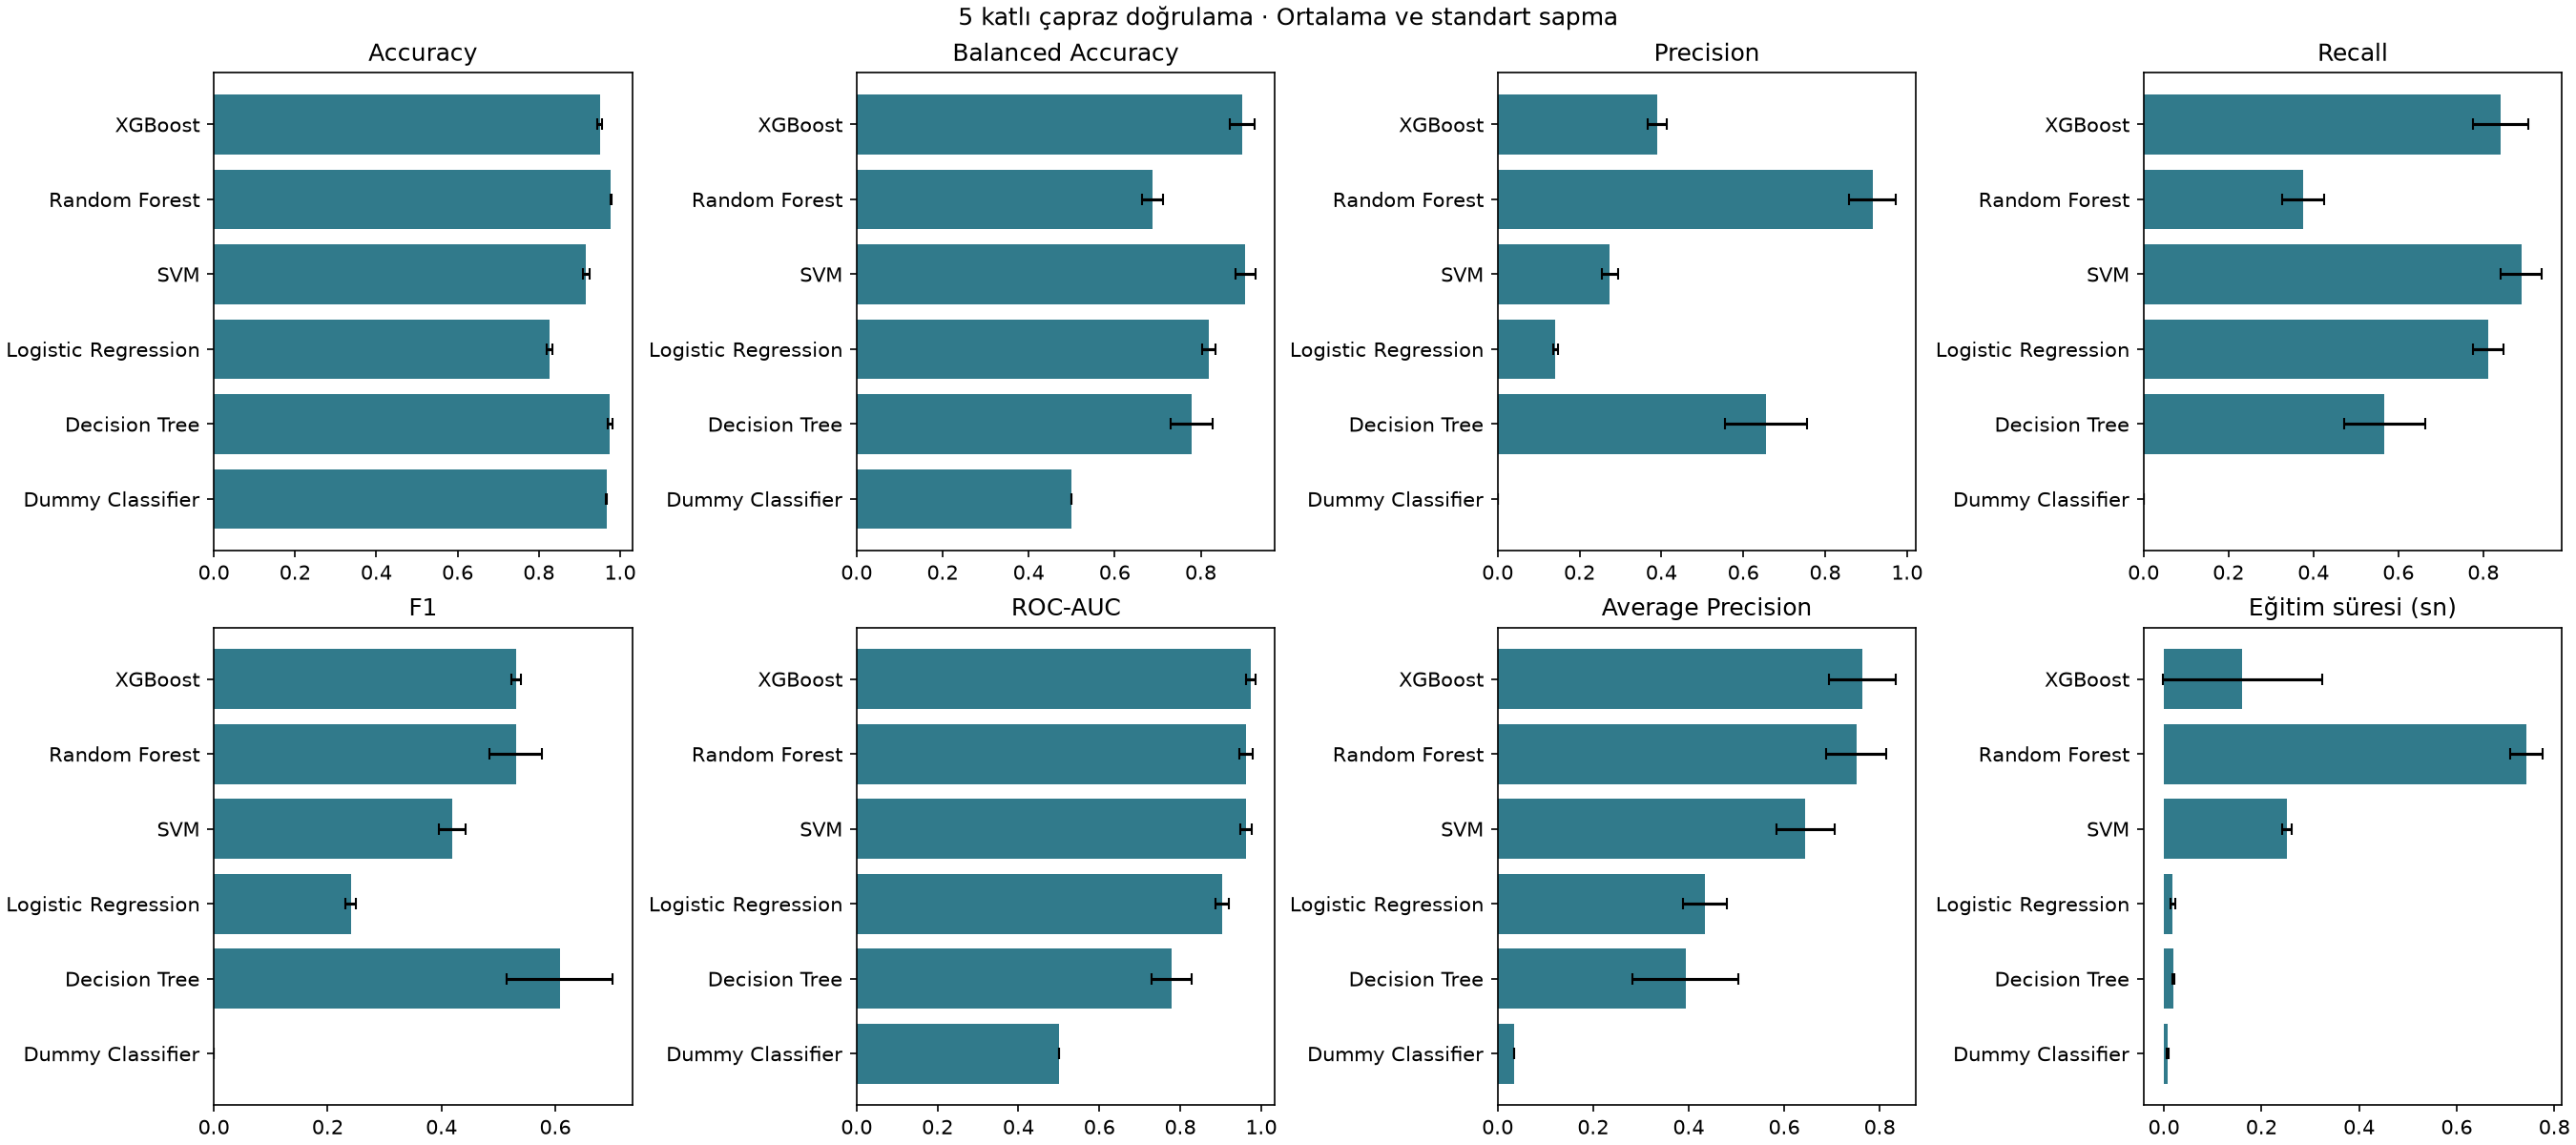

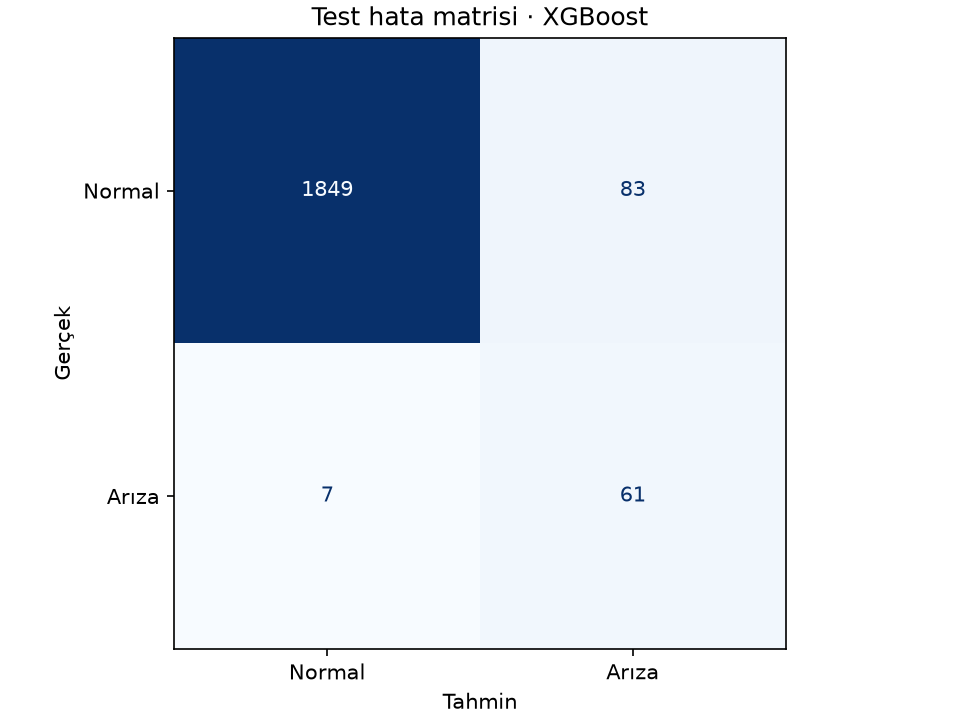

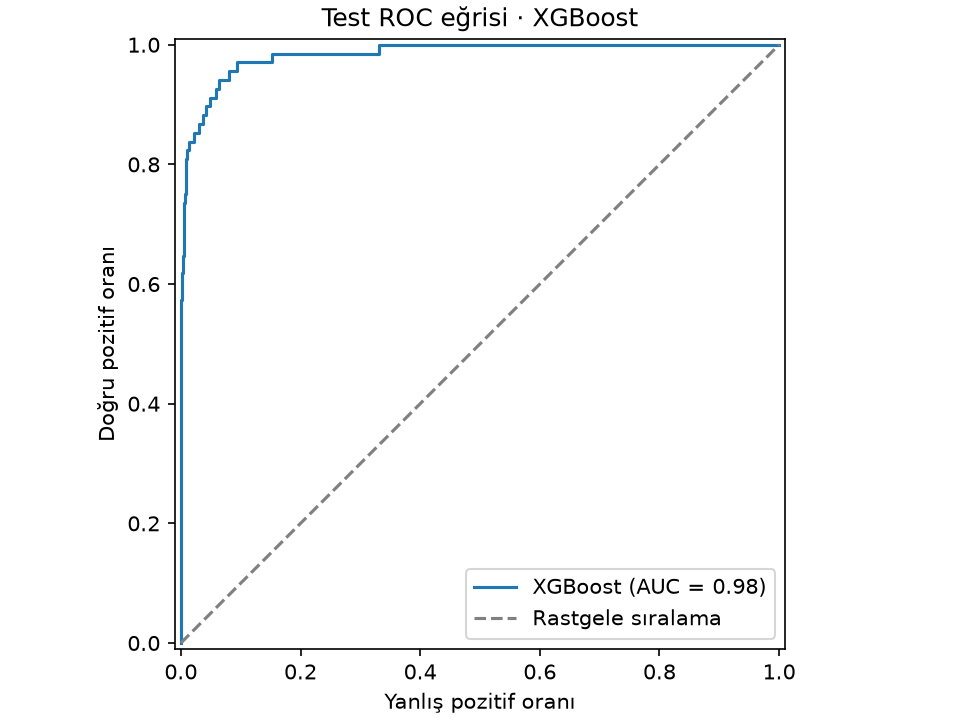

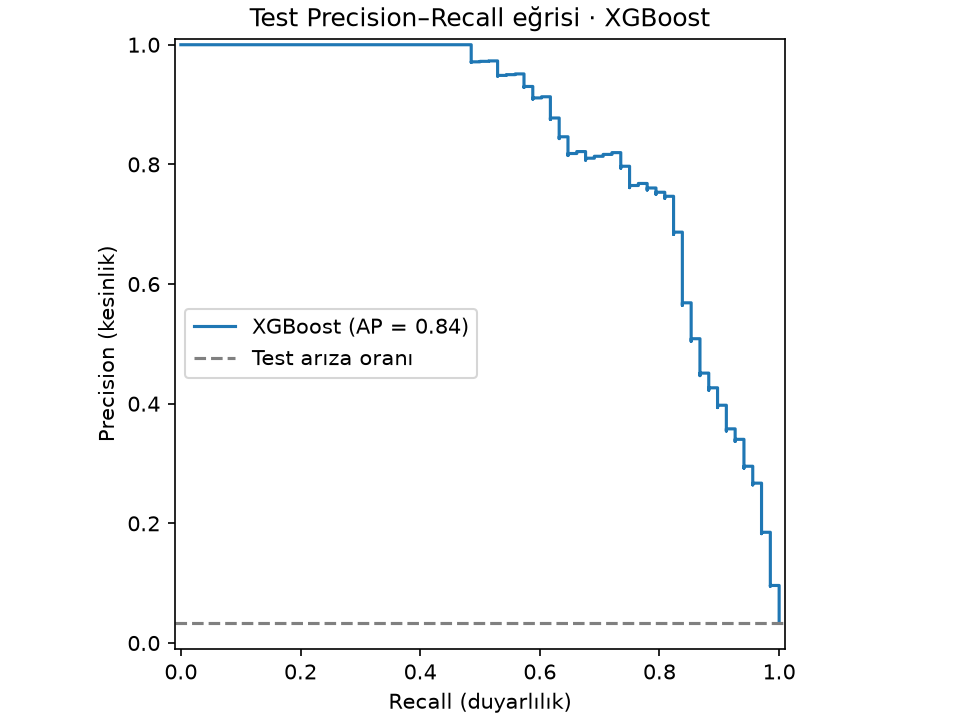

In [6]:
save_results(comparison, winner, test_metrics, matrix, y_test, scores)
for filename in (
    "model_comparison.png", "confusion_matrix.png",
    "roc_curve.png", "precision_recall_curve.png",
):
    display(Image(filename=str(RESULTS / filename), width=1050 if filename == "model_comparison.png" else 620))